# 01 · Zrozumienie problemu i danych (CRISP-DM, etapy 1–2)

**Projekt:** odporność rozpoznawania znaków drogowych na zakłócenia i ataki (zbiór GTSRB)
**Kurs:** Metody AI w badaniu zagrożeń w systemach komputerowych
**Zespół:** [Imię Nazwisko], [Imię Nazwisko], [Imię Nazwisko]

Ten notatnik realizuje dwa pierwsze etapy metodyki CRISP-DM:

1. **Business Understanding** – po co rozwiązujemy ten problem, kto i jak może zaatakować system, co uznamy za sukces.
2. **Data Understanding** – co jest w zbiorze, jak wyglądają dane, jakie mają problemy i co z tego wynika dla dalszych etapów.

**Dane:** rozpakowany zbiór GTSRB (wersja z Kaggle / Zenodo) w katalogu `data/GTSRB/`:

```
data/GTSRB/
├── Train/0 … Train/42/    obrazy treningowe, nazwa pliku: <klasa>_<seria>_<klatka>.png
├── Test/                  obrazy testowe
├── Meta/                  wzorcowy obraz każdej klasy
├── Train.csv  Test.csv  Meta.csv
```

Foldery pisane małą literą (`train/`, `test/`, `meta/`) są w archiwum kopiami – notatnik sprawdza to w sekcji 2.1 i z nich nie korzysta. Inną lokalizację danych można wskazać zmienną środowiskową `GTSRB_DIR`.

**Jak uruchomić:** z katalogu głównego repozytorium `jupyter notebook`, w przeglądarce otworzyć ten plik i wybrać *Kernel → Restart Kernel and Run All Cells*. Odczyt ok. 50 tys. obrazów trwa kilka minut. Notatnik nie wymaga GPU.

**Co powstaje po uruchomieniu:**
- wykresy w `reports/figures/` (gotowe do wklejenia w prezentację i raport),
- tabela metadanych obrazów w `data/processed/meta.csv` (używana w notatniku 02 – Data Preparation).

### Spis treści
0. Konfiguracja środowiska
1. Business Understanding
   1.1 Cele biznesowe · 1.2 Ocena sytuacji · 1.3 Model zagrożeń · 1.4 Cele analityczne i kryteria sukcesu · 1.5 Plan projektu
2. Data Understanding
   2.1 Pozyskanie danych · 2.2 Opis danych · 2.3 Eksploracja · 2.4 Weryfikacja jakości · 2.5 Podsumowanie i wnioski

## 0. Konfiguracja środowiska

Importy, stałe ziarno losowości (powtarzalność wyników) i wersje bibliotek. Wspólne stałe i funkcje (nazwy klas, ścieżki, ładowanie danych) są w `src/gtsrb_utils.py`, żeby kolejne notatniki korzystały z tego samego kodu.

In [1]:
import sys, io, time, hashlib, platform
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap
from PIL import Image
from matplotlib.patches import Rectangle
from tqdm import tqdm  # zwykły pasek tekstowy, nie wymaga ipywidgets

import gtsrb_utils as gu

gu.set_seed()
gu.ensure_dirs()
pd.set_option("display.max_rows", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def wrap(text, width=24):
    "Łamie długi podpis wykresu na linie zamiast go ucinać."
    return "\n".join(textwrap.wrap(text, width))

GROUP_COLORS = dict(zip(gu.GROUP_ORDER, ["#c8372d", "#8b1e3f", "#8a939c", "#e08a2e", "#d4b106", "#2f6fb0"]))

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__}")
print("Katalog z danymi:", gu.GTSRB_DIR)

Python 3.14.8 | numpy 2.5.4 | pandas 3.1.0
Katalog z danymi: /home/wojtazk/Desktop/gtsrb-robustness/data/GTSRB


---
# 1. Business Understanding

## 1.1 Cele biznesowe

**Kontekst.** Rozpoznawanie znaków drogowych (*Traffic Sign Recognition*, TSR) działa dziś w zwykłych samochodach, nie tylko w autonomicznych. Od lipca 2024 r. każdy nowo rejestrowany samochód w UE musi mieć inteligentny asystent prędkości (ISA, rozporządzenie 2019/2144), który odczytuje ograniczenia m.in. z kamery. Na podstawie odczytu działają ostrzeżenia dla kierowcy, adaptacyjny tempomat, a w pojazdach autonomicznych – decyzje o hamowaniu i jeździe.

**Problem.** Klasyfikator znaków to model uczenia maszynowego, a jego wejściem jest świat fizyczny dostępny dla każdego. Pomyłkę może wywołać:
- przyroda i sprzęt: mgła, deszcz, rozmycie ruchu, słabe oświetlenie, kompresja obrazu;
- celowy przeciwnik: naklejki lub taśma na znaku (udokumentowane ataki na prawdziwe systemy, m.in. Eykholt i in. 2018, McAfee 2020), niewidoczne dla człowieka zaburzenia obrazu albo zatrute dane treningowe.

**Cel biznesowy projektu.** Ocenić, na ile klasyfikatory znaków trenowane na GTSRB są odporne na naturalne zakłócenia i ataki adwersarialne, które pomyłki są najgroźniejsze dla bezpieczeństwa ruchu, oraz sprawdzić proste metody obrony i wykrywania podejrzanych wejść.

**Kto korzysta z wyników (interesariusze):**

| Interesariusz | Czego potrzebuje |
|---|---|
| producent systemu ADAS / pojazdu | wiedzy, w jakich warunkach model zawodzi i jak go wzmocnić |
| zespół bezpieczeństwa (red team) | listy realnych wektorów ataku i ich skuteczności |
| kierowca / pasażer | systemu, który nie przyspieszy przez naklejkę na znaku |
| prowadzący kurs | reprodukowalnego eksperymentu z porównaniem metod i literatury |

## 1.2 Ocena sytuacji

**Zasoby**

| Zasób | Stan |
|---|---|
| Dane | GTSRB (Zenodo, rekord 13741936 / Kaggle): obrazy treningowe w 43 folderach, obrazy testowe, wzorce klas oraz pliki CSV z rozmiarem obrazu, ramką znaku (ROI) i klasą |
| Sprzęt | laptopy zespołu (CPU) do analizy danych; Google Colab / GPU do trenowania sieci – *[uzupełnić]* |
| Zespół | [2–3] osoby, ok. 3 h projektu tygodniowo + praca własna |
| Narzędzia | Python, Jupyter, pandas, Pillow, scikit-learn, PyTorch, torchattacks lub Adversarial Robustness Toolbox, biblioteka do generowania zakłóceń (np. `imagecorruptions` lub `albumentations`) |

**Wymagania (z zasad kursu)**
- Python + Jupyter Notebook, kod możliwy do uruchomienia i **reprodukowalny** (stałe ziarno, zapisane wersje bibliotek).
- Metryki odpowiednie dla zbioru (niezbalansowane klasy → nie tylko accuracy).
- Porównanie kilku klasyfikatorów, w tym **czasu uczenia i inferencji**.
- Porównanie z wynikami z literatury, analiza istotności cech (interpretowalność).
- Kamienie milowe co 2 tygodnie, raport końcowy z kodem, dwie prezentacje na seminarium.

**Założenia**
- Etykiety w GTSRB są poprawne (zbiór był ręcznie anotowany i jest standardowym benchmarkiem).
- Wycięte zdjęcia znaków dobrze przybliżają wejście klasyfikatora w prawdziwym systemie (etap detekcji znaku na pełnej klatce pomijamy).
- Zakłócenia, które sami wygenerujemy (szum, rozmycie, mgła, zmiana jasności, kompresja JPEG, okluzja – wzorem Hendrycks i Dietterich 2019), dobrze przybliżają warunki drogowe.

**Ograniczenia**
- Nie mamy dostępu do prawdziwego samochodu ani komercyjnego systemu – ataki fizyczne symulujemy cyfrowo (np. łatki/naklejki na obrazie).
- Ograniczona moc obliczeniowa → małe obrazy (32×32 lub 48×48) i umiarkowanie duże sieci.
- Tylko znaki niemieckie (bardzo podobne do polskich, ale nie identyczne).
- Zbiór nie zawiera gotowych obrazów z zakłóceniami – generujemy je sami. Zaletą jest pełna kontrola nad rodzajem i siłą zakłócenia.

**Ryzyka i plan awaryjny**

| Ryzyko | Skutek | Plan awaryjny |
|---|---|---|
| wyciek danych między treningiem a walidacją (serie zdjęć tego samego znaku) | zawyżone wyniki walidacji | podział po seriach (sekcja 2.4), ocena na oficjalnym teście |
| brak GPU / zbyt długi trening | opóźnienie | mniejsza rozdzielczość, transfer learning, Colab |
| ataki adwersarialne trywialnie skuteczne (100%) | mało ciekawych wniosków | krzywe skuteczności w funkcji siły ataku ε, ataki celowane, porównanie modeli i obron |
| różnice wersji bibliotek w zespole | kod nie działa u innych | `requirements.txt`, uruchamianie *Restart & Run All* przed commitem |

**Słowniczek**

| Termin | Znaczenie |
|---|---|
| TSR / ADAS / ISA | rozpoznawanie znaków / systemy wspomagania kierowcy / inteligentny asystent prędkości |
| atak unikowy (*evasion*) | zmiana wejścia wytrenowanego modelu tak, by się pomylił |
| atak celowany | wymuszenie konkretnej błędnej klasy (np. STOP → ograniczenie prędkości) |
| zatruwanie danych, backdoor | podmiana części danych treningowych, by model nauczył się ukrytej reguły |
| ε (epsilon) | maksymalna dopuszczalna zmiana piksela w ataku (np. 8/255) |
| FGSM / PGD | podstawowe ataki gradientowe (Goodfellow i in. 2015; Madry i in. 2018) |
| robustness | odporność modelu na zakłócenia i ataki |

## 1.3 Model zagrożeń (*threat model*)

W cyberbezpieczeństwie analizę zaczyna się od pytania, **kto**, **czym** i **po co** atakuje system. Dla klasyfikatora znaków:

| Element | Opis dla naszego problemu |
|---|---|
| Zasób chroniony | poprawna decyzja pojazdu (prędkość, zatrzymanie, kierunek jazdy) |
| Cel atakującego | wymusić niebezpieczną pomyłkę: atak celowany (STOP → „jedź”) lub dowolną pomyłkę (obniżenie dostępności funkcji) |
| Wiedza atakującego | *white-box* (zna model i wagi – najgorszy przypadek, nasze eksperymenty) albo *black-box* (tylko obserwuje decyzje auta) |
| Możliwości | cyfrowe: zmiana pikseli w zakresie ε; fizyczne: naklejki, taśma, farba, projekcja światła na znak; łańcuch dostaw: zatrute dane treningowe |
| Moment ataku | inferencja (ataki unikowe, naturalne zakłócenia) albo trening (zatruwanie, backdoor) |
| Ograniczenie atakującego | zmiana ma być niewidoczna lub wyglądać niewinnie dla człowieka (graffiti, brud) |

**Koszt pomyłek nie jest równy.** Pomylenie STOP z ograniczeniem prędkości jest groźniejsze niż 30 z 50 km/h. Dlatego oprócz accuracy będziemy analizować macierz pomyłek z podziałem na grupy znaków (sekcja 2.2) i wskazywać pomyłki krytyczne.

| Przykładowa pomyłka | Skutek | Ryzyko (propozycja zespołu) |
|---|---|---|
| STOP → dowolny inny znak | auto nie zatrzymuje się | krytyczne |
| zakaz wjazdu → nakaz jazdy prosto | wjazd pod prąd | krytyczne |
| 30 → 80 km/h | przyspieszenie w terenie zabudowanym | wysokie |
| 30 → 50 km/h | umiarkowane przekroczenie | średnie |
| zakręt w lewo → zakręt w prawo | błędne ostrzeżenie | niskie |

## 1.4 Cele analityczne i kryteria sukcesu

Cel biznesowy przekładamy na konkretne zadania uczenia maszynowego:

| # | Zadanie analityczne | Typ zadania | Miara |
|---|---|---|---|
| A1 | klasyfikacja znaku do jednej z 43 klas | uczenie nadzorowane, wieloklasowe | accuracy, **macro-F1**, macierz pomyłek |
| A2 | ocena odporności na naturalne zakłócenia generowane w kilku poziomach siły | ewaluacja | accuracy dla każdego zakłócenia i poziomu, spadek względem czystego testu |
| A3 | ataki adwersarialne FGSM / PGD (także celowane) | ewaluacja bezpieczeństwa | accuracy pod atakiem i skuteczność ataku w funkcji ε |
| A4 | obrona: trening adwersarialny / augmentacja | uczenie nadzorowane | kompromis: czysta accuracy vs odporność |
| A5 | wykrywanie zaburzonych wejść jako anomalii | uczenie nienadzorowane (kNN, LOF, Isolation Forest na cechach sieci) | AUROC |
| A6 | interpretowalność | analiza modelu | mapy Grad-CAM: na co patrzy model przy poprawnej i błędnej decyzji |
| A7 | koszt obliczeniowy | pomiar | czas uczenia i inferencji (ms / obraz) |

**Kryteria sukcesu** *(progi są propozycją zespołu – do zatwierdzenia z prowadzącym)*:
- A1: accuracy na czystym teście ≥ 97%, dla porównania: człowiek 98,84%, najlepsza sieć w konkursie IJCNN 2011 99,46% (Stallkamp i in. 2012);
- A2–A3: pełne krzywe accuracy w funkcji zakłócenia / ε dla co najmniej dwóch modeli i wskazanie najgroźniejszych zakłóceń;
- A4: obrona poprawia accuracy pod atakiem PGD (ε = 8/255) o co najmniej [10] p.p.;
- A5: detektor anomalii z AUROC wyraźnie powyżej 0,5 dla co najmniej jednego typu zaburzenia;
- cały projekt odtwarzalny z repozytorium jedną komendą *Run All* w każdym notatniku.

## 1.5 Plan projektu

| Etap CRISP-DM | Notatnik | Zakres | Krok z kursu | Kamień milowy |
|---|---|---|---|---|
| 1. Business Understanding | `01_…` (ten) | cele, model zagrożeń, kryteria sukcesu | 1, 2 | M1 – [data] |
| 2. Data Understanding | `01_…` (ten) | eksploracja, jakość danych | 1, 3 | M1 – [data] |
| 3. Data Preparation | `02_data_preparation` | skalowanie, normalizacja, podział po seriach, balans klas | 4 | M2 – [data] |
| 4. Modeling | `03_baseline_models` | CNN od zera, transfer learning, model klasyczny na cechach; czasy | 5 | M3 – [data] |
| 4. Modeling | `04_robustness_corruptions` | zakłócenia generowane w 5 poziomach siły: szum, rozmycie, mgła, jasność, JPEG, okluzja | 5 | M3 – [data] |
| 4. Modeling | `05_adversarial_attacks` | FGSM, PGD, ataki celowane, trening adwersarialny | 5 | M4 – [data] |
| 4. Modeling | `06_anomaly_detection` | wykrywanie zaburzonych wejść metodami nienadzorowanymi | 6 | M4 – [data] |
| 5. Evaluation | `07_evaluation_interpretability` | porównanie modeli, literatura, Grad-CAM | 5d, 5e | M5 – [data] |
| 6. Deployment *(opcjonalnie, ocena 5.5)* | `08_demo` | prosta aplikacja demonstracyjna, test na innym zbiorze znaków | – | raport końcowy |

---
# 2. Data Understanding

## 2.1 Pozyskanie danych

Korzystamy z oryginalnego zbioru GTSRB (Stallkamp i in. 2012) w wersji z Zenodo (rekord 13741936, licencja CC BY 4.0) / Kaggle. Zbiór jest rozpakowany w `data/GTSRB/`.

Najpierw inwentarz: co jest w katalogu, ile plików i ile miejsca zajmuje. Archiwum zawiera foldery w dwóch wersjach (np. `Train` i `train`) – sprawdzamy, czy to kopie.

In [2]:
import os

DATA = gu.check_data_dir()

def folder_stats(p):
    files = [f for f in p.rglob("*") if f.is_file()]
    return len(files), sum(f.stat().st_size for f in files) / 2**20

inventory = []
for p in sorted(DATA.iterdir()):
    n, mb = folder_stats(p) if p.is_dir() else (1, p.stat().st_size / 2**20)
    inventory.append({"element": p.name, "typ": "folder" if p.is_dir() else "plik",
                      "liczba plików": n, "rozmiar [MB]": round(mb, 1)})
pd.DataFrame(inventory)

,element,typ,liczba plików,rozmiar [MB]
0,Meta,folder,45,0.3
1,Meta.csv,plik,1,0.0
2,Test,folder,12631,72.5
3,Test.csv,plik,1,0.4
4,Train,folder,39209,224.7
5,Train.csv,plik,1,1.9
6,meta,folder,45,0.3
7,test,folder,12631,72.5
8,train,folder,39209,224.7


In [3]:
# Pliki w folderach Train / Test / Meta, które nie są obrazami (np. dodatkowe CSV lub pliki pomocnicze z archiwum)
IMAGE_EXT = {".png", ".ppm", ".jpg", ".jpeg"}
for name in ["Train", "Test", "Meta"]:
    other = sorted(str(f.relative_to(DATA)) for f in (DATA / name).rglob("*") if f.is_file() and f.suffix.lower() not in IMAGE_EXT)
    print(f"{name}: {len(other)} plików innych niż obrazy" + (": " + ", ".join(other[:10]) if other else ""))

Train: 0 plików innych niż obrazy
Test: 1 plików innych niż obrazy: Test/GT-final_test.csv
Meta: 2 plików innych niż obrazy: Meta/.~lock.ClassesInformation.ods#, Meta/.~lock.ClassesInformationStrong.ods#


In [4]:
def file_md5(path):
    return hashlib.md5(open(path, "rb").read()).hexdigest()

for name in ["Train", "Test", "Meta"]:
    up, low = DATA / name, DATA / name.lower()
    if not low.exists() or low.samefile(up):
        print(f"{name:5s}: brak osobnej kopii pisanej małą literą")
        continue
    files_up = {f.relative_to(up) for f in up.rglob("*") if f.is_file()}
    files_low = {f.relative_to(low) for f in low.rglob("*") if f.is_file()}
    common = sorted(files_up & files_low)
    sample = [common[i] for i in np.random.default_rng(gu.SEED).choice(len(common), size=min(50, len(common)), replace=False)] if common else []
    same_content = all(file_md5(up / f) == file_md5(low / f) for f in sample)
    verdict = "KOPIA (te same pliki) – notatnik używa wersji z wielkiej litery" if files_up == files_low and same_content else "RÓŻNICE – sprawdzić ręcznie"
    print(f"{name:5s} vs {name.lower():5s}: {len(files_up)} vs {len(files_low)} plików, "
          f"zgodna treść próbki {len(sample)} plików: {same_content} -> {verdict}")

Train vs train: 39209 vs 39209 plików, zgodna treść próbki 50 plików: True -> KOPIA (te same pliki) – notatnik używa wersji z wielkiej litery
Test  vs test : 12631 vs 12631 plików, zgodna treść próbki 50 plików: True -> KOPIA (te same pliki) – notatnik używa wersji z wielkiej litery
Meta  vs meta : 45 vs 45 plików, zgodna treść próbki 45 plików: True -> KOPIA (te same pliki) – notatnik używa wersji z wielkiej litery


In [5]:
train_df, test_df, meta_df = gu.load_tables()

splits = pd.DataFrame({
    "podzbiór": ["trening (Train.csv)", "test (Test.csv)", "wzorce klas (Meta.csv)"],
    "liczba wierszy": [len(train_df), len(test_df), len(meta_df)],
    "liczba klas": [train_df["label"].nunique(), test_df["label"].nunique(), meta_df["ClassId"].nunique()],
})
splits

,podzbiór,liczba wierszy,liczba klas
0,trening (Train.csv),39209,43
1,test (Test.csv),12630,43
2,wzorce klas (Meta.csv),43,43


In [6]:
train_df.head()

,split,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,label,file,roi_w,roi_h,track,frame,track_id
0,train,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png,20,/home/wojtazk/Desktop/gtsrb-robustness/data/GT...,17,15,0,0,20_0
1,train,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png,20,/home/wojtazk/Desktop/gtsrb-robustness/data/GT...,18,16,0,1,20_0
2,train,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png,20,/home/wojtazk/Desktop/gtsrb-robustness/data/GT...,18,16,0,2,20_0
3,train,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png,20,/home/wojtazk/Desktop/gtsrb-robustness/data/GT...,18,16,0,3,20_0
4,train,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png,20,/home/wojtazk/Desktop/gtsrb-robustness/data/GT...,18,16,0,4,20_0


## 2.2 Opis danych

### Kolumny w plikach CSV
Cechami modelu będą **piksele obrazów**. Pliki CSV opisują obrazy (metadane), nie są cechami do klasyfikacji – z wyjątkiem ramki znaku, którą wykorzystamy przy przygotowaniu danych.

| Kolumna | Plik | Znaczenie |
|---|---|---|
| `Width`, `Height` | Train, Test | rozmiar obrazu w pikselach |
| `Roi.X1`, `Roi.Y1`, `Roi.X2`, `Roi.Y2` | Train, Test | ramka (ROI) samego znaku na obrazie: lewy górny i prawy dolny róg |
| `ClassId` | wszystkie | klasa znaku 0–42 (**etykieta**) |
| `Path` | wszystkie | ścieżka do pliku obrazu względem `data/GTSRB` |
| `ShapeId`, `ColorId`, `SignId` | Meta | kody kształtu, koloru i identyfikator znaku – znaczenie kodów odczytujemy z obrazów wzorcowych poniżej |

Kolumny dodane przez `gu.load_tables()`: `label` (= `ClassId`), `file` (pełna ścieżka), `roi_w`, `roi_h` (wymiary ramki) oraz dla treningu `track` i `frame` odczytane z nazwy pliku `<klasa>_<seria>_<klatka>.png` i `track_id` = klasa + seria (unikalny identyfikator fizycznego znaku).

In [7]:
num_cols = ["Width", "Height", "Roi.X1", "Roi.Y1", "Roi.X2", "Roi.Y2", "roi_w", "roi_h"]
pd.concat({"trening": train_df[num_cols].describe().T, "test": test_df[num_cols].describe().T}).round(1)

count  mean   std   min   25%   50%   75%    max
trening Width   39209.0  50.8  24.3  25.0  35.0  43.0  58.0  243.0
        Height  39209.0  50.3  23.1  25.0  35.0  43.0  58.0  225.0
        Roi.X1  39209.0   6.0   1.5   0.0   5.0   6.0   6.0   20.0
        Roi.Y1  39209.0   6.0   1.4   5.0   5.0   6.0   6.0   20.0
        Roi.X2  39209.0  45.2  23.1  20.0  29.0  38.0  53.0  223.0
        Roi.Y2  39209.0  44.7  22.0  20.0  30.0  38.0  52.0  205.0
        roi_w   39209.0  39.2  21.8  15.0  24.0  33.0  47.0  203.0
        roi_h   39209.0  38.8  20.8  15.0  24.0  32.0  47.0  185.0
test    Width   12630.0  50.5  25.1  25.0  34.0  43.0  58.0  266.0
        Height  12630.0  50.4  23.7  25.0  35.0  43.0  57.0  232.0
        Roi.X1  12630.0   6.0   1.5   1.0   5.0   6.0   6.0   23.0
        Roi.Y1  12630.0   6.0   1.4   5.0   5.0   6.0   6.0   19.0
        Roi.X2  12630.0  44.9  23.8  20.0  29.0  38.0  53.0  244.0
        Roi.Y2  12630.0  44.8  22.5  20.0  29.0  38.0  52.0  212.0
        roi_w   12630.0  38.9  22.5  15.0  23.0  32.0  47.0  222.0
        roi_h   12630.0  38.8  21.3  15.0  24.0  32.0  47.0  193.0

### Klasy i obrazy wzorcowe (Meta)
`Meta/` zawiera po jednym wzorcowym rysunku każdej klasy. Na tej podstawie sprawdzamy, czy polskie nazwy klas w `gu.CLASS_NAMES_PL` pasują do numerów klas – **przejrzyjcie siatkę wzrokowo**. Jeśli któryś podpis nie zgadza się z rysunkiem, poprawcie listę w `src/gtsrb_utils.py`.

In [8]:
classes = meta_df[["ClassId", "ShapeId", "ColorId", "SignId"]].copy()
classes["SignId"] = classes["SignId"].fillna("–")   # brak kodu w Meta.csv
classes["nazwa PL"] = classes["ClassId"].map(lambda c: gu.CLASS_NAMES_PL[c])
classes["grupa"] = classes["ClassId"].map(gu.CLASS_GROUP)
classes["obrazy treningowe"] = classes["ClassId"].map(train_df["label"].value_counts()).fillna(0).astype(int)
classes["serie (znaki fizyczne)"] = classes["ClassId"].map(train_df.groupby("label")["track_id"].nunique()).fillna(0).astype(int)
classes["obrazy testowe"] = classes["ClassId"].map(test_df["label"].value_counts()).fillna(0).astype(int)
classes

,ClassId,ShapeId,ColorId,SignId,nazwa PL,grupa,obrazy treningowe,serie (znaki fizyczne),obrazy testowe
0,0,1,0,3.29,ograniczenie 20 km/h,ograniczenia prędkości,210,7,60
1,1,1,0,3.29,ograniczenie 30 km/h,ograniczenia prędkości,2220,74,720
2,2,1,0,3.29,ograniczenie 50 km/h,ograniczenia prędkości,2250,75,750
3,3,1,0,3.29,ograniczenie 60 km/h,ograniczenia prędkości,1410,47,450
4,4,1,0,3.29,ograniczenie 70 km/h,ograniczenia prędkości,1980,66,660
5,5,1,0,3.29,ograniczenie 80 km/h,ograniczenia prędkości,1860,62,630
6,6,1,3,3.3,koniec ograniczenia 80 km/h,ograniczenia prędkości,420,14,150
7,7,1,0,3.29,ograniczenie 100 km/h,ograniczenia prędkości,1440,48,450
8,8,1,0,3.29,ograniczenie 120 km/h,ograniczenia prędkości,1410,47,450
9,9,1,0,3.25,zakaz wyprzedzania,zakazy,1470,49,480


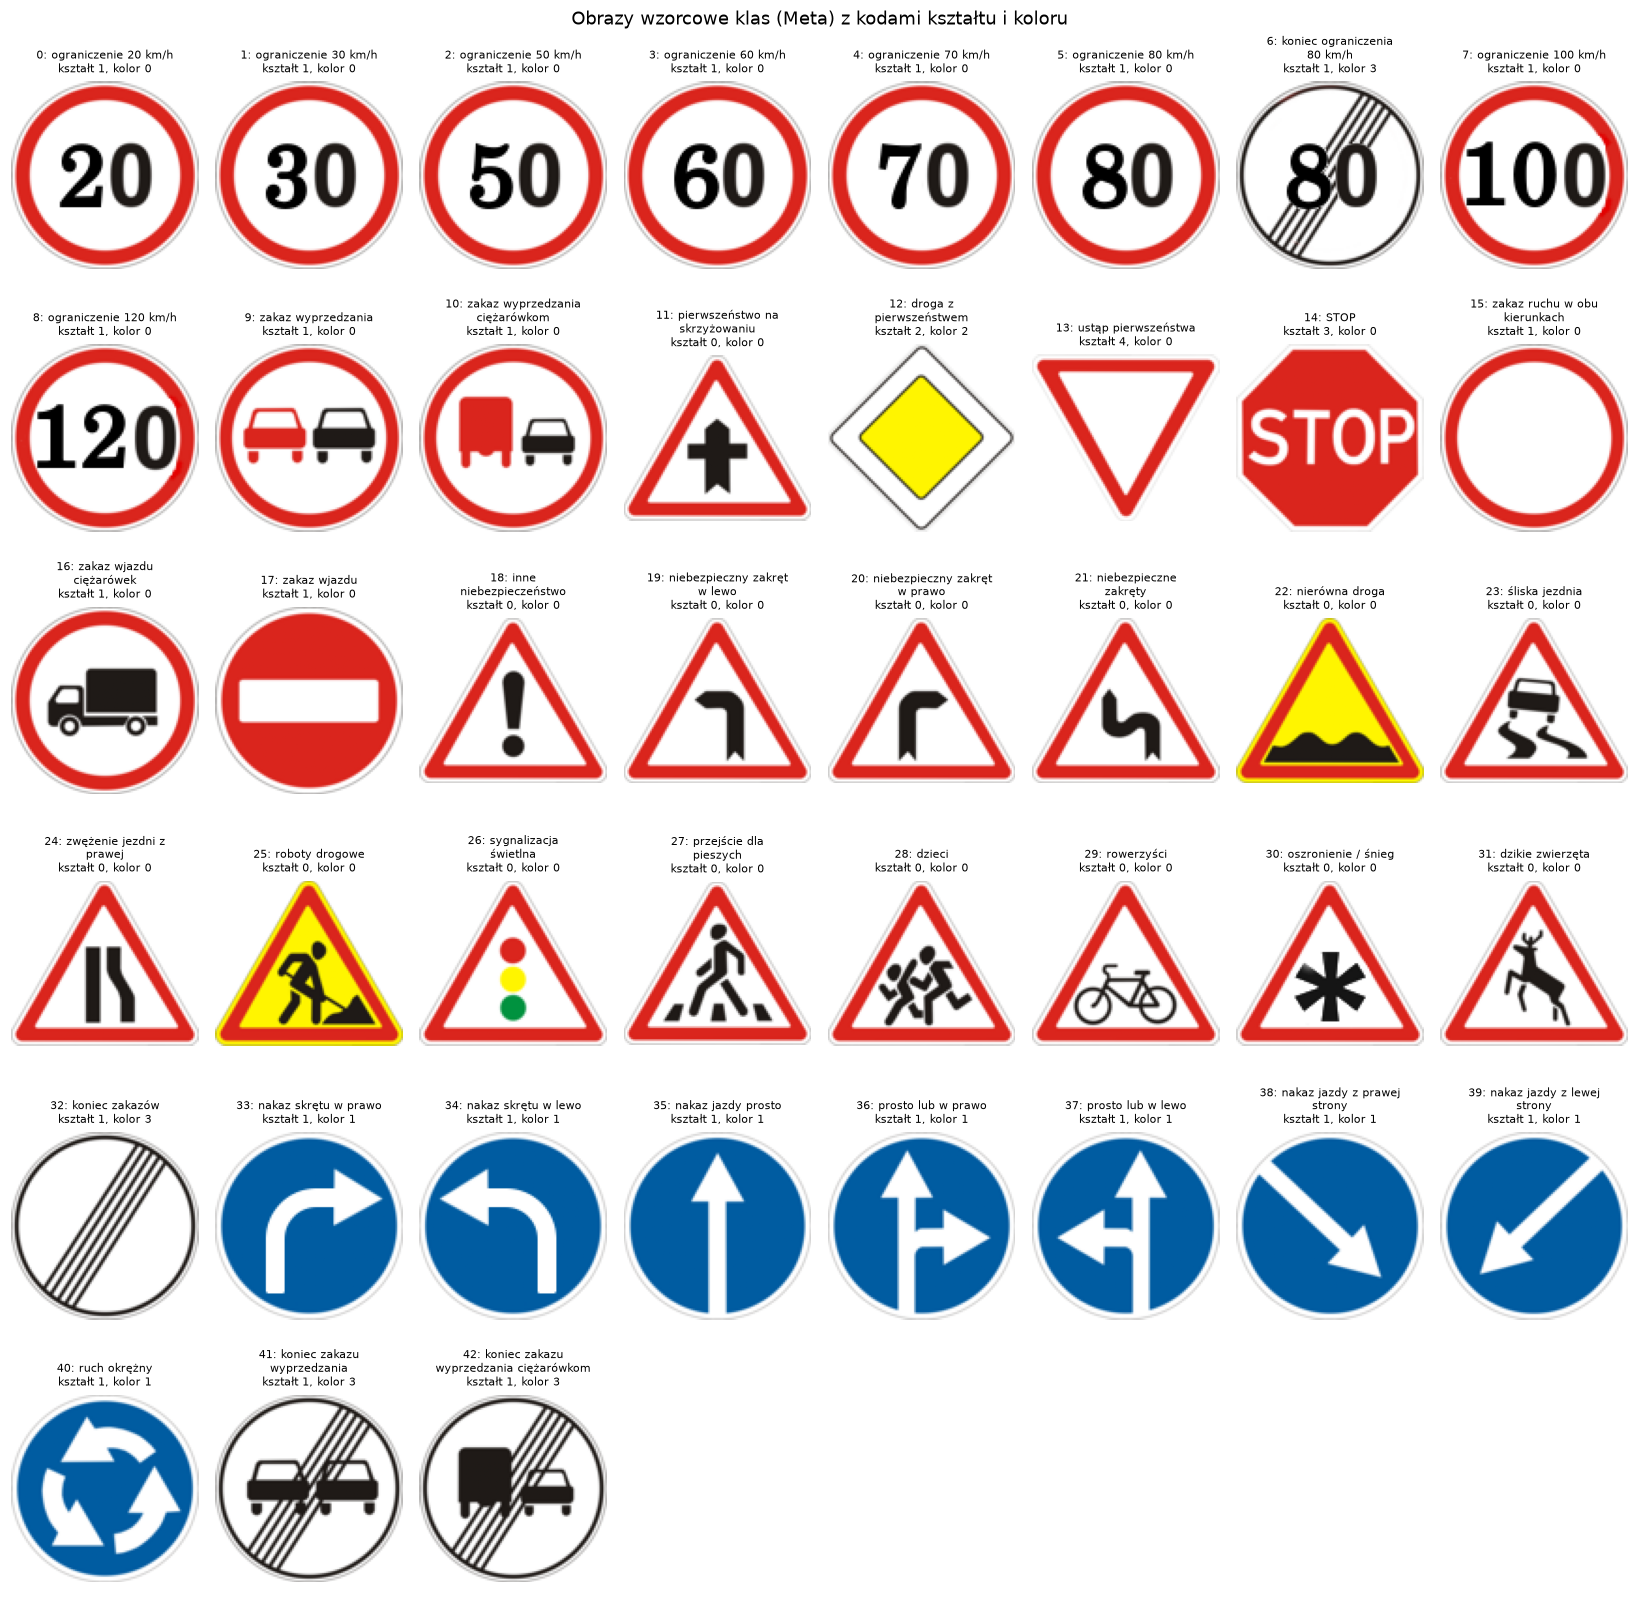

Klasy według kodu kształtu (wiersze) i koloru (kolumny); puste pole = brak takiej kombinacji:


ColorId,0,1,2,3
ShapeId,,,,
0,"11, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28...",,,
1,"0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 15, 16, 17","33, 34, 35, 36, 37, 38, 39, 40",,"6, 32, 41, 42"
2,,,12,
3,14,,,
4,13,,,


In [9]:
fig, axes = plt.subplots(6, 8, figsize=(15, 15))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, r) in zip(axes.flat, meta_df.iterrows()):
    with Image.open(r["file"]) as im:
        ax.imshow(im.convert("RGBA"))
    ax.set_title(f"{wrap(str(r['ClassId']) + ': ' + gu.CLASS_NAMES_PL[r['ClassId']])}\nkształt {r['ShapeId']}, kolor {r['ColorId']}", fontsize=7)
fig.suptitle("Obrazy wzorcowe klas (Meta) z kodami kształtu i koloru")
fig.tight_layout()
gu.savefig(fig, "01_meta_reference")
plt.show()

print("Klasy według kodu kształtu (wiersze) i koloru (kolumny); puste pole = brak takiej kombinacji:")
(pd.crosstab(meta_df["ShapeId"], meta_df["ColorId"], values=meta_df["ClassId"],
             aggfunc=lambda s: ", ".join(map(str, sorted(s))))
   .fillna(""))

### Metadane obrazów
Otwieramy każdy plik z `Train.csv` i `Test.csv` i zapisujemy: format, tryb kolorów, rzeczywisty rozmiar, średnią jasność, kontrast (odchylenie standardowe jasności), skrót MD5 pikseli (do wykrywania duplikatów) oraz miniaturę 32×32 do dalszej analizy. Przy okazji wyłapujemy pliki brakujące i uszkodzone.

Trwa to kilka minut.

In [10]:
THUMB = 32

def scan(df):
    rows = []
    thumbs = np.zeros((len(df), THUMB, THUMB, 3), dtype=np.uint8)
    for i, f in enumerate(tqdm(df["file"], desc=df["split"].iat[0], total=len(df), file=sys.stdout)):
        r = {"exists": os.path.exists(f), "readable": False}
        if r["exists"]:
            try:
                with Image.open(f) as im:
                    r.update(format=im.format, mode=im.mode)
                    img = im.convert("RGB")
                gray = np.asarray(img.convert("L"), dtype=np.float32) / 255
                r.update(readable=True, real_w=img.width, real_h=img.height,
                         brightness=gray.mean(), contrast=gray.std(),
                         md5=hashlib.md5(img.tobytes()).hexdigest())
                thumbs[i] = np.asarray(img.resize((THUMB, THUMB)))
            except Exception as e:  # uszkodzony plik
                r["error"] = repr(e)
        rows.append(r)
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(rows)], axis=1), thumbs

meta_train, thumbs_train = scan(train_df)
meta_test, thumbs_test = scan(test_df)
meta = pd.concat([meta_train, meta_test], ignore_index=True)
meta["group"] = meta["label"].map(gu.CLASS_GROUP)
meta[["split", "Path", "label", "track_id", "real_w", "real_h", "brightness", "contrast"]].head()

test: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████| 12630/12630 [00:03<00:00, 3544.42it/s]


,split,Path,label,track_id,real_w,real_h,brightness,contrast
0,train,Train/20/00020_00000_00000.png,20,20_0,27,26,0.229138,0.045828
1,train,Train/20/00020_00000_00001.png,20,20_0,28,27,0.231020,0.045477
2,train,Train/20/00020_00000_00002.png,20,20_0,29,26,0.230613,0.044715
3,train,Train/20/00020_00000_00003.png,20,20_0,28,27,0.228084,0.045317
4,train,Train/20/00020_00000_00004.png,20,20_0,28,26,0.222080,0.039787


In [11]:
print("Format plików:", meta["format"].value_counts(dropna=False).to_dict())
print("Tryb kolorów:", meta["mode"].value_counts(dropna=False).to_dict())
meta.groupby("split")[["real_w", "real_h", "brightness", "contrast"]].describe().T.round(3)

Format plików: {'PNG': 51839}
Tryb kolorów: {'RGB': 51839}


split                  test      train
real_w     count  12630.000  39209.000
           mean      50.508     50.836
           std       25.088     24.307
           min       25.000     25.000
           25%       34.000     35.000
           50%       43.000     43.000
           75%       58.000     58.000
           max      266.000    243.000
real_h     count  12630.000  39209.000
           mean      50.364     50.329
           std       23.699     23.115
           min       25.000     25.000
           25%       35.000     35.000
           50%       43.000     43.000
           75%       57.000     58.000
           max      232.000    225.000
brightness count  12630.000  39209.000
           mean       0.319      0.322
           std        0.183      0.187
           min        0.035      0.024
           25%        0.176      0.171
           50%        0.287      0.292
           75%        0.436      0.446
           max        0.937      0.974
contrast   count  12630.000  39209.000
           mean       0.166      0.165
           std        0.095      0.096
           min        0.015      0.008
           25%        0.084      0.081
           50%        0.159      0.156
           75%        0.241      0.242
           max        0.441      0.446

## 2.3 Eksploracja danych

### Rozkład klas
Kluczowe pytanie dla kursu (*class-imbalanced data*): jak bardzo niezbalansowane są klasy i czy rozkład w teście jest podobny do treningowego.

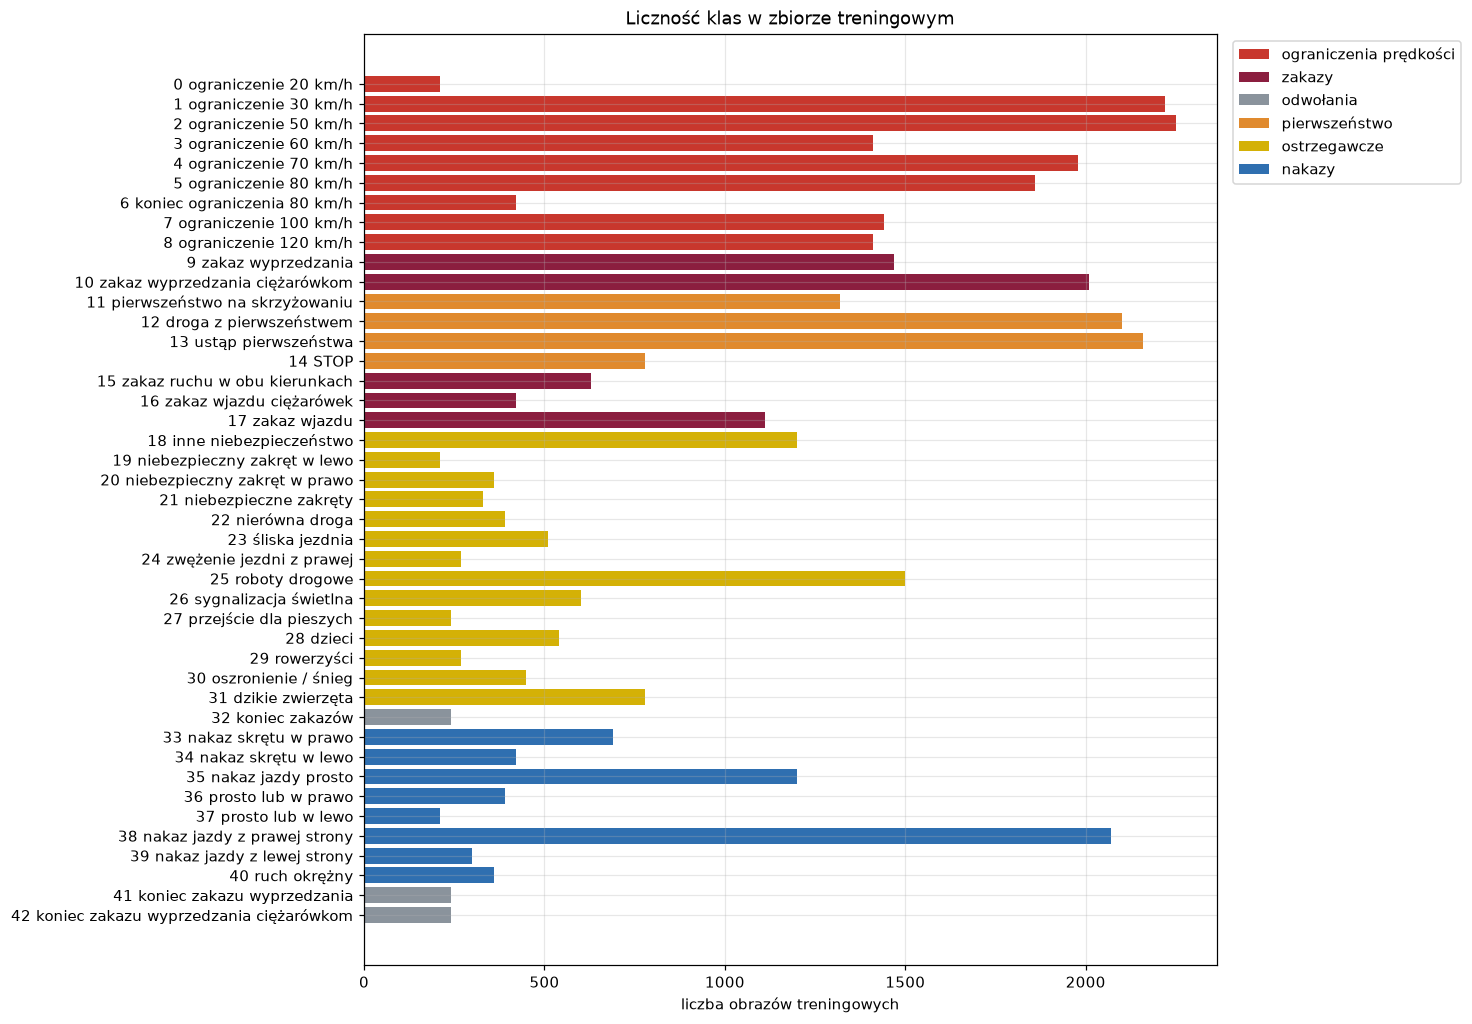

Najliczniejsza klasa: 2 (2250 obrazów)
Najmniej liczna klasa: 0 (210 obrazów)
Współczynnik niezbalansowania (max/min): 10.7


In [12]:
counts = (meta.groupby(["label", "split"]).size().unstack(fill_value=0)
              .reindex(range(43), fill_value=0))
counts["nazwa"] = gu.CLASS_NAMES_PL
counts["grupa"] = [gu.CLASS_GROUP[i] for i in range(43)]

fig, ax = plt.subplots(figsize=(10, 11))
colors = [GROUP_COLORS[g] for g in counts["grupa"]]
ax.barh([f"{i:2d} {n}" for i, n in zip(counts.index, counts["nazwa"])], counts["train"], color=colors)
ax.invert_yaxis()
ax.set_xlabel("liczba obrazów treningowych")
ax.set_title("Liczność klas w zbiorze treningowym")
for g, c in GROUP_COLORS.items():
    ax.barh(0, 0, color=c, label=g)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
gu.savefig(fig, "01_class_distribution")
plt.show()

imbalance = counts["train"].max() / counts["train"].min()
print(f"Najliczniejsza klasa: {counts['train'].idxmax()} ({counts['train'].max()} obrazów)")
print(f"Najmniej liczna klasa: {counts['train'].idxmin()} ({counts['train'].min()} obrazów)")
print(f"Współczynnik niezbalansowania (max/min): {imbalance:.1f}")

Korelacja udziałów klas trening vs test: 0.999  (blisko 1 = podobny rozkład)


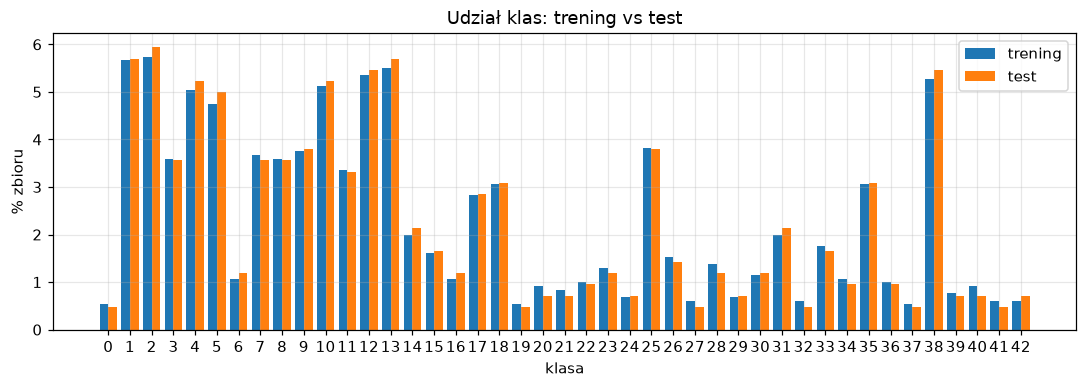

split,train,test
grupa,,
ograniczenia prędkości,13200,4320
zakazy,5640,1860
odwołania,720,210
pierwszeństwo,6360,2100
ostrzegawcze,7650,2370
nakazy,5639,1770


In [13]:
share = counts[["train", "test"]] / counts[["train", "test"]].sum()
corr = share["train"].corr(share["test"])
print(f"Korelacja udziałów klas trening vs test: {corr:.3f}  (blisko 1 = podobny rozkład)")

fig, ax = plt.subplots(figsize=(12, 3.5))
x = np.arange(43)
ax.bar(x - 0.2, share["train"] * 100, width=0.4, label="trening")
ax.bar(x + 0.2, share["test"] * 100, width=0.4, label="test")
ax.set_xticks(x)
ax.set_xlabel("klasa")
ax.set_ylabel("% zbioru")
ax.set_title("Udział klas: trening vs test")
ax.legend()
gu.savefig(fig, "01_class_share_train_test")
plt.show()

counts.groupby("grupa")[["train", "test"]].sum().reindex(gu.GROUP_ORDER)

### Przykładowe obrazy
Jeden losowy obraz z każdej klasy. Zwróćcie uwagę na różnice w oświetleniu, ostrości i kadrowaniu.

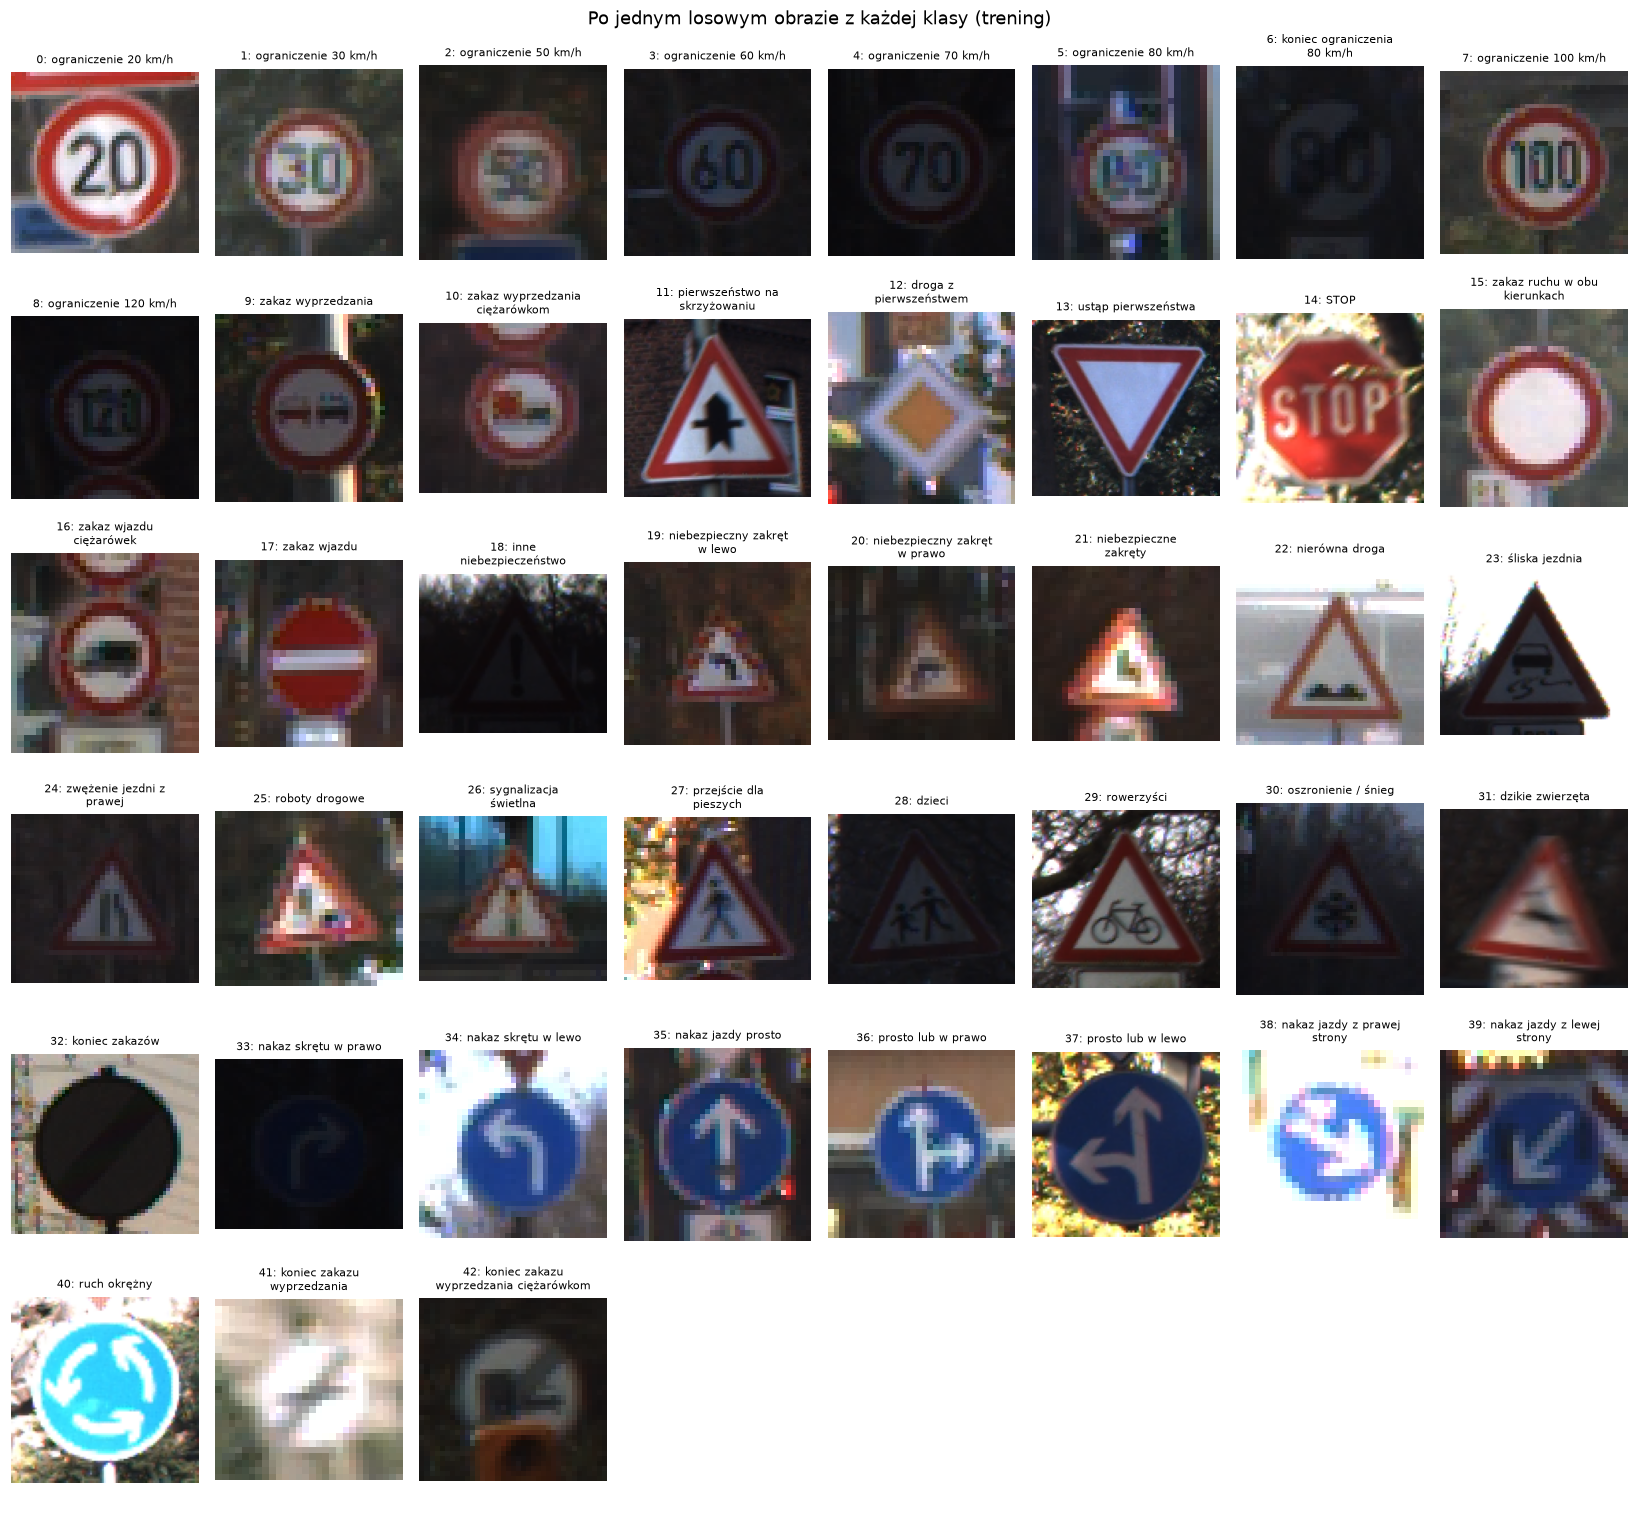

In [14]:
rng = np.random.default_rng(gu.SEED)
fig, axes = plt.subplots(6, 8, figsize=(15, 14))
for ax in axes.flat:
    ax.axis("off")
for cid, ax in zip(range(43), axes.flat):
    idx = rng.choice(meta_train.index[(meta_train["label"] == cid) & meta_train["readable"]])
    ax.imshow(gu.load_image(meta_train.loc[idx, "file"]))
    ax.set_title(wrap(f"{cid}: {gu.CLASS_NAMES_PL[cid]}"), fontsize=7)
fig.suptitle("Po jednym losowym obrazie z każdej klasy (trening)")
fig.tight_layout()
gu.savefig(fig, "01_examples_per_class")
plt.show()

### Serie zdjęć tego samego znaku
Nazwa pliku treningowego ma postać `<klasa>_<seria>_<klatka>.png`. Jedna seria to kolejne klatki nagrania **tego samego fizycznego znaku**, gdy samochód się do niego zbliża. Oznacza to, że liczba naprawdę różnych znaków jest dużo mniejsza niż liczba obrazów – i że losowy podział obrazów na trening i walidację umieściłby prawie identyczne zdjęcia po obu stronach.

Liczba serii (fizycznych znaków) w treningu: 1307
Klatek na serię: mediana 30, min 29, max 30
Serii na klasę: min 7 (klasa 0), max 75 (klasa 2)


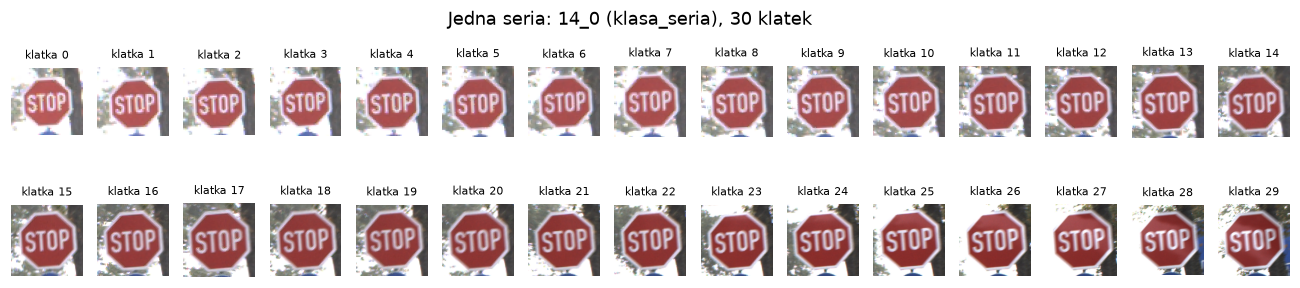

In [15]:
track_sizes = meta_train.groupby("track_id").size()
tracks_per_class = meta_train.groupby("label")["track_id"].nunique()

print(f"Liczba serii (fizycznych znaków) w treningu: {track_sizes.size}")
print(f"Klatek na serię: mediana {track_sizes.median():.0f}, min {track_sizes.min()}, max {track_sizes.max()}")
print(f"Serii na klasę: min {tracks_per_class.min()} (klasa {tracks_per_class.idxmin()}), max {tracks_per_class.max()} (klasa {tracks_per_class.idxmax()})")

example_track = meta_train.loc[meta_train["label"] == 14, "track_id"].dropna()
example_track = example_track.iat[0] if len(example_track) else meta_train["track_id"].dropna().iat[0]
frames = meta_train[meta_train["track_id"] == example_track].sort_values("frame")
n = len(frames)
cols = 15
fig, axes = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(15, 1.2 * np.ceil(n / cols) + 0.6), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, (_, r) in zip(axes.flat, frames.iterrows()):
    ax.imshow(gu.load_image(r["file"]))
    ax.set_title(f"klatka {r['frame']}", fontsize=7)
fig.suptitle(f"Jedna seria: {example_track} (klasa_seria), {n} klatek")
gu.savefig(fig, "01_example_track")
plt.show()

### Rozmiary obrazów i ramka znaku (ROI)
Sieci wymagają wejścia o stałym rozmiarze, więc trzeba wybrać docelową rozdzielczość. Bardzo małe obrazy tracą szczegóły (np. cyfry na ograniczeniach prędkości). Ramka ROI pokazuje, ile miejsca na obrazie zajmuje sam znak, a ile tło – od tego zależy, czy w przygotowaniu danych wycinać znak.

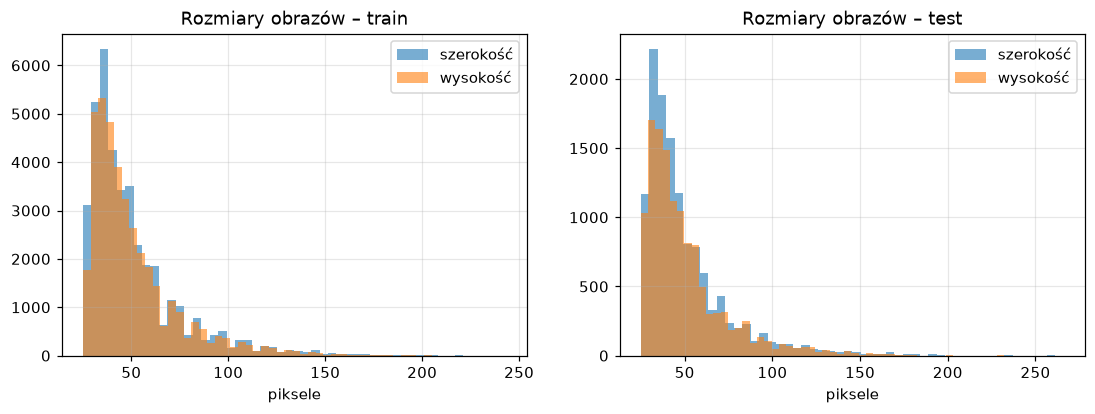

Obrazy o krótszym boku < 32 px:  17.0%
Obrazy o krótszym boku < 48 px:  61.7%
Obrazy o krótszym boku < 64 px:  82.3%
Proporcje (szer./wys.): mediana 1.00, zakres 0.37–1.44


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for split, ax in zip(["train", "test"], axes):
    m = meta[meta["split"] == split]
    ax.hist(m["real_w"], bins=50, alpha=0.6, label="szerokość")
    ax.hist(m["real_h"], bins=50, alpha=0.6, label="wysokość")
    ax.set_title(f"Rozmiary obrazów – {split}")
    ax.set_xlabel("piksele")
    ax.legend()
gu.savefig(fig, "01_image_sizes")
plt.show()

min_side = meta[["real_w", "real_h"]].min(axis=1)
for t in (32, 48, 64):
    print(f"Obrazy o krótszym boku < {t:2d} px: {(min_side < t).mean():6.1%}")
aspect = meta["real_w"] / meta["real_h"]
print(f"Proporcje (szer./wys.): mediana {aspect.median():.2f}, zakres {aspect.min():.2f}–{aspect.max():.2f}")

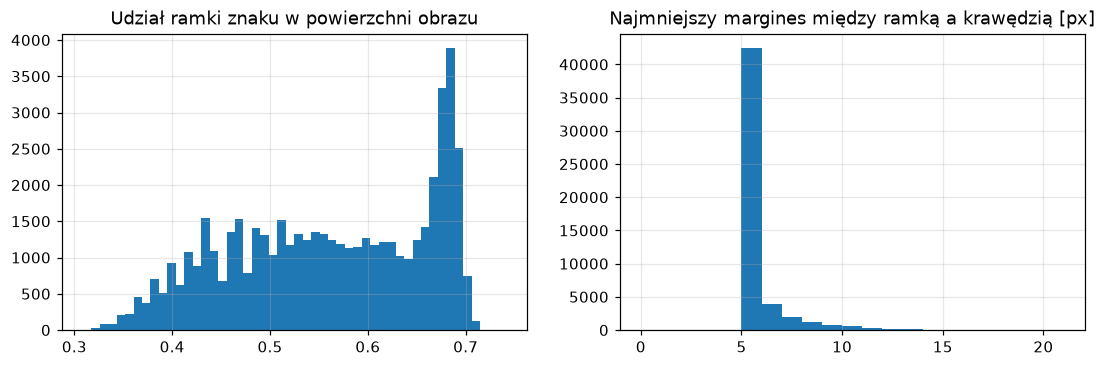

Mediana udziału znaku w obrazie: 57%, mediana marginesu: 5 px


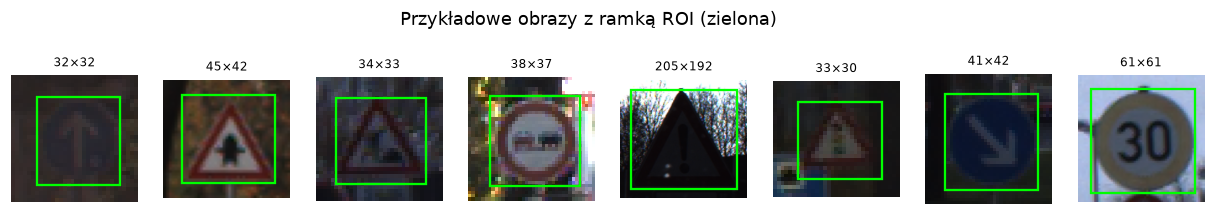

In [17]:
meta["roi_area_frac"] = meta["roi_w"] * meta["roi_h"] / (meta["Width"] * meta["Height"])
meta["roi_margin"] = meta[["Roi.X1", "Roi.Y1"]].min(axis=1).combine(
    pd.concat([meta["Width"] - meta["Roi.X2"], meta["Height"] - meta["Roi.Y2"]], axis=1).min(axis=1), min)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(meta["roi_area_frac"], bins=50)
axes[0].set_title("Udział ramki znaku w powierzchni obrazu")
axes[1].hist(meta["roi_margin"], bins=range(0, int(meta["roi_margin"].max()) + 2))
axes[1].set_title("Najmniejszy margines między ramką a krawędzią [px]")
gu.savefig(fig, "01_roi_stats")
plt.show()
print(f"Mediana udziału znaku w obrazie: {meta['roi_area_frac'].median():.0%}, mediana marginesu: {meta['roi_margin'].median():.0f} px")

fig, axes = plt.subplots(1, 8, figsize=(14, 2.4))
for ax, i in zip(axes, rng.choice(meta_train.index[meta_train["readable"]], size=8, replace=False)):
    r = meta_train.loc[i]
    ax.imshow(gu.load_image(r["file"]))
    ax.add_patch(Rectangle((r["Roi.X1"], r["Roi.Y1"]), r["roi_w"], r["roi_h"], fill=False, edgecolor="lime", linewidth=1.5))
    ax.set_title(f"{r['real_w']}×{r['real_h']}", fontsize=8)
    ax.axis("off")
fig.suptitle("Przykładowe obrazy z ramką ROI (zielona)")
gu.savefig(fig, "01_roi_examples")
plt.show()

### Jasność i kontrast
Ciemne i mało kontrastowe zdjęcia są trudne dla modelu i dla człowieka. To także naturalny „przeciwnik”: zła pogoda i noc.

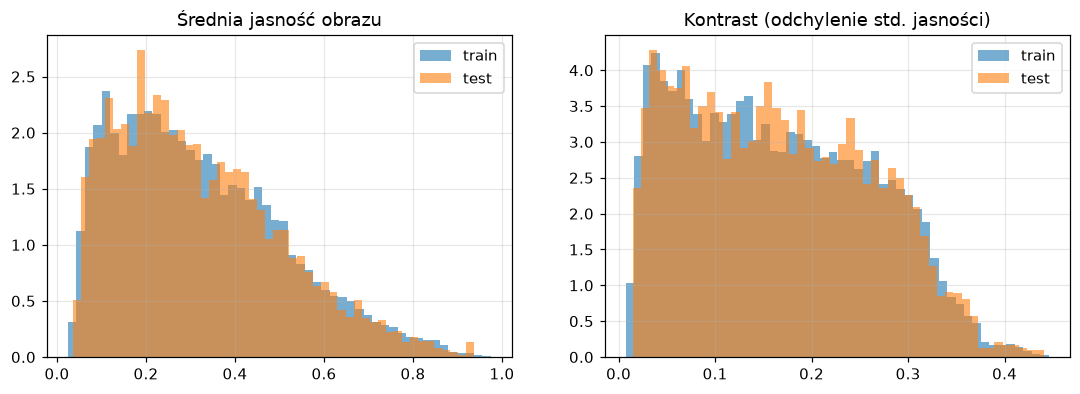

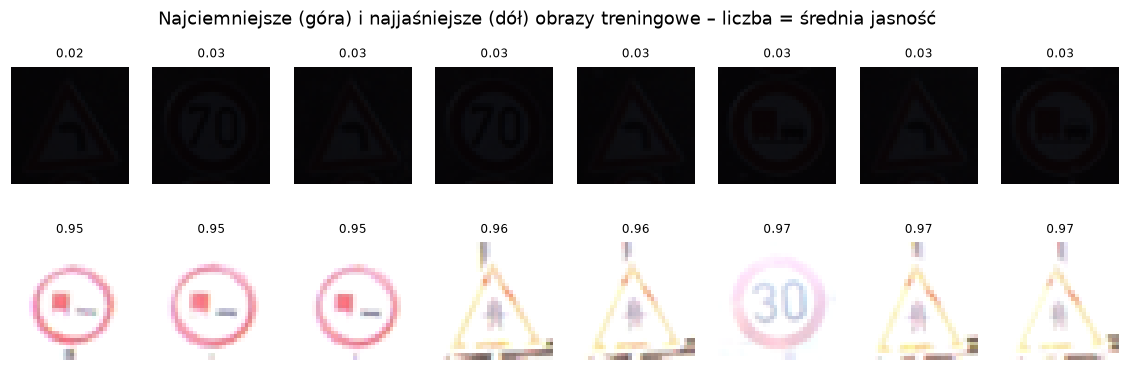

Obrazy bardzo ciemne (jasność < 0.15): 20.5%


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for split in ["train", "test"]:
    m = meta[meta["split"] == split]
    axes[0].hist(m["brightness"], bins=50, alpha=0.6, density=True, label=split)
    axes[1].hist(m["contrast"], bins=50, alpha=0.6, density=True, label=split)
axes[0].set_title("Średnia jasność obrazu")
axes[1].set_title("Kontrast (odchylenie std. jasności)")
for ax in axes:
    ax.legend()
gu.savefig(fig, "01_brightness_contrast")
plt.show()

order = meta_train[meta_train["readable"]].sort_values("brightness")
picks = list(order.index[:8]) + list(order.index[-8:])
fig, axes = plt.subplots(2, 8, figsize=(13, 3.8))
for ax, i in zip(axes.flat, picks):
    ax.imshow(thumbs_train[i])
    ax.set_title(f"{meta_train.loc[i, 'brightness']:.2f}", fontsize=8)
    ax.axis("off")
fig.suptitle("Najciemniejsze (góra) i najjaśniejsze (dół) obrazy treningowe – liczba = średnia jasność")
gu.savefig(fig, "01_darkest_brightest")
plt.show()

print("Obrazy bardzo ciemne (jasność < 0.15):", f"{(meta['brightness'] < 0.15).mean():.1%}")

### Średni obraz klasy
Uśrednione miniatury 32×32 pokazują, co jest stałe dla klasy (kształt, kolor obramowania), a co zmienne. Klasy z bardzo podobnymi średnimi obrazami (np. ograniczenia prędkości) będą najczęściej mylone.

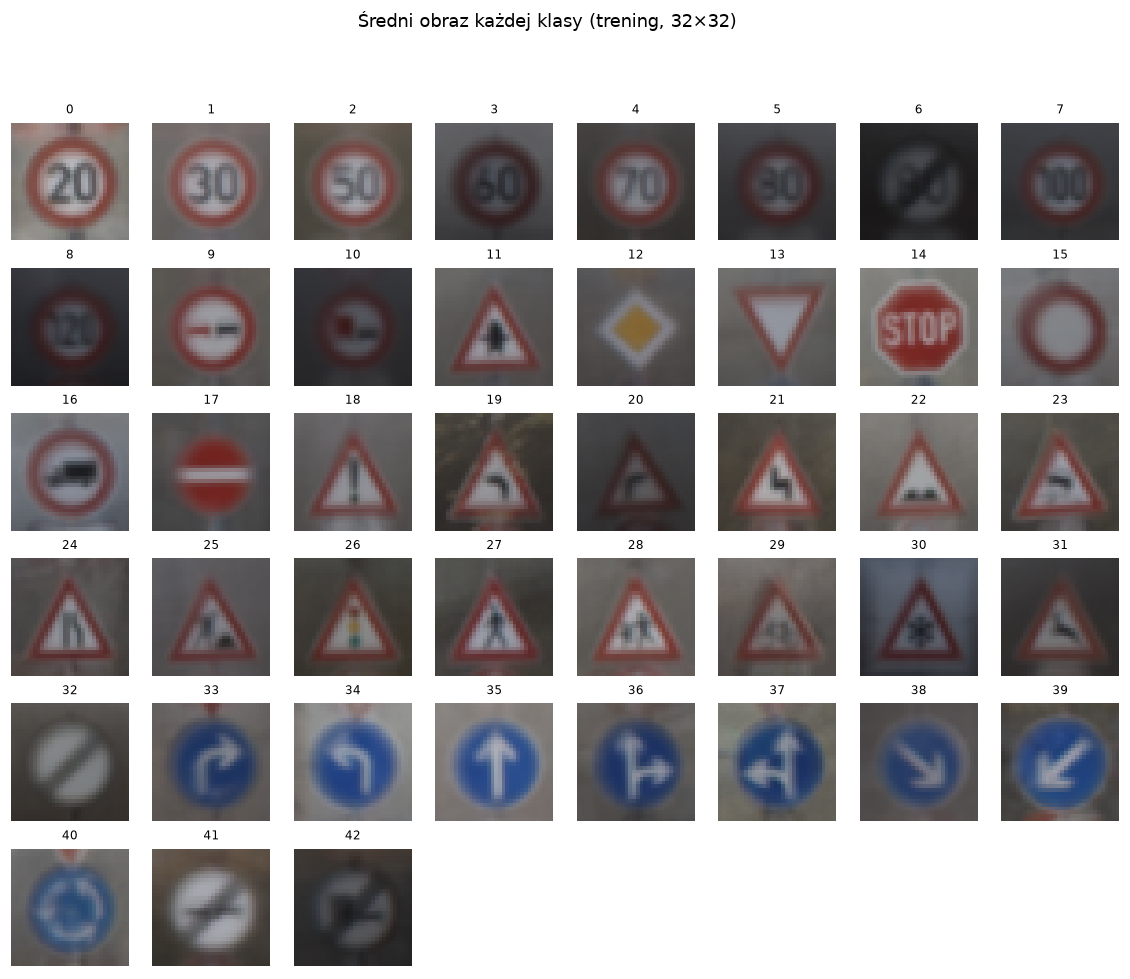

In [19]:
fig, axes = plt.subplots(6, 8, figsize=(13, 10))
for ax in axes.flat:
    ax.axis("off")
for cid, ax in zip(range(43), axes.flat):
    mask = ((meta_train["label"] == cid) & meta_train["readable"]).to_numpy()
    if mask.any():
        ax.imshow(thumbs_train[mask].mean(axis=0).astype(np.uint8))
    ax.set_title(str(cid), fontsize=8)
fig.suptitle("Średni obraz każdej klasy (trening, 32×32)")
gu.savefig(fig, "01_mean_image_per_class")
plt.show()

### Struktura danych w przestrzeni pikseli (PCA)
Redukcja wymiaru (temat kursu) na surowych pikselach: 32×32×3 = 3072 cechy. Sprawdzamy, ile składowych wyjaśnia większość wariancji i czy grupy znaków dają się rozdzielić liniowo. Słaby podział uzasadnia użycie sieci konwolucyjnych zamiast klasyfikatora liniowego na pikselach.

Składowe potrzebne do 90% wariancji: 43 (z 3072 cech)


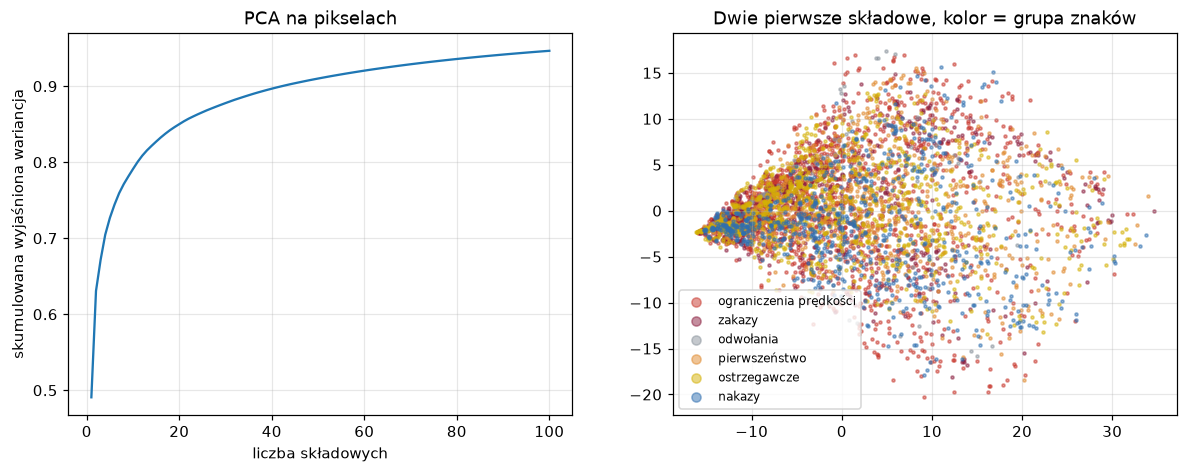

In [20]:
from sklearn.decomposition import PCA

valid = np.flatnonzero(meta_train["readable"].to_numpy())
n = min(5000, len(valid))
sample_idx = rng.choice(valid, size=n, replace=False)
X = thumbs_train[sample_idx].reshape(n, -1).astype(np.float32) / 255
groups = meta_train.loc[sample_idx, "group"].to_numpy() if "group" in meta_train else meta_train.loc[sample_idx, "label"].map(gu.CLASS_GROUP).to_numpy()

pca = PCA(n_components=min(100, n), random_state=gu.SEED).fit(X)
cum = np.cumsum(pca.explained_variance_ratio_)
k90 = int(np.searchsorted(cum, 0.90) + 1) if cum[-1] >= 0.90 else None
print(f"Składowe potrzebne do 90% wariancji: {k90 if k90 else '> ' + str(len(cum))} (z 3072 cech)")

Z = pca.transform(X)[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(np.arange(1, len(cum) + 1), cum)
axes[0].set_xlabel("liczba składowych")
axes[0].set_ylabel("skumulowana wyjaśniona wariancja")
axes[0].set_title("PCA na pikselach")
for g in gu.GROUP_ORDER:
    m = groups == g
    axes[1].scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.5, color=GROUP_COLORS[g], label=g)
axes[1].set_title("Dwie pierwsze składowe, kolor = grupa znaków")
axes[1].legend(markerscale=3, fontsize=8)
gu.savefig(fig, "01_pca")
plt.show()

## 2.4 Weryfikacja jakości danych

Sprawdzamy kompletność i spójność danych (CSV ↔ pliki), poprawność ramek ROI oraz rzeczy, które mogą po cichu zawyżyć wyniki: duplikaty i przeciek między treningiem a testem.

In [21]:
csv_files = set(os.path.normpath(f) for f in meta["file"])
disk_files = {os.path.normpath(str(f)) for sub in ("Train", "Test") for f in (DATA / sub).rglob("*")
              if f.is_file() and f.suffix.lower() in (".png", ".ppm", ".jpg", ".jpeg")}

folder_class = meta_train["Path"].str.extract(r"Train[/\\](\d+)[/\\]")[0].astype(float)
name_class = meta_train["Path"].str.extract(r"(\d+)_\d+_\d+\.\w+$")[0].astype(float)
readable = meta["readable"]

quality = {
    "brak etykiety": int(meta["label"].isna().sum()),
    "etykieta spoza 0–42": int((~meta["label"].between(0, 42)).sum()),
    "pliki z CSV, których nie ma na dysku": int((~meta["exists"]).sum()),
    "pliki nieczytelne (uszkodzone)": int((meta["exists"] & ~readable).sum()),
    "obrazy na dysku nieopisane w CSV": len(disk_files - csv_files),
    "trening: folder klasy ≠ ClassId": int((folder_class != meta_train["label"]).sum()),
    "trening: klasa w nazwie pliku ≠ ClassId": int((name_class != meta_train["label"]).sum()),
    "trening: nazwy plików bez numeru serii": int(meta_train["track"].isna().sum()),
    "rozmiar w CSV ≠ rzeczywisty": int(((meta["Width"] != meta["real_w"]) | (meta["Height"] != meta["real_h"]))[readable].sum()),
    "ramka ROI niepoprawna lub poza obrazem": int(((meta["Roi.X1"] < 0) | (meta["Roi.Y1"] < 0) | (meta["roi_w"] <= 0) | (meta["roi_h"] <= 0)
                                                   | (meta["Roi.X2"] > meta["Width"]) | (meta["Roi.Y2"] > meta["Height"])).sum()),
    "duplikaty w treningu (identyczne piksele)": int(meta_train.loc[meta_train["readable"], "md5"].duplicated().sum()),
    "duplikaty w teście": int(meta_test.loc[meta_test["readable"], "md5"].duplicated().sum()),
    "obrazy testowe identyczne z treningowymi (przeciek)": int(meta_test["md5"].dropna().isin(set(meta_train["md5"].dropna())).sum()),
    "obrazy o krótszym boku < 25 px": int((min_side < 25).sum()),
}
quality_df = pd.Series(quality, name="liczba").to_frame()
quality_df

,liczba
brak etykiety,0
etykieta spoza 0–42,0
"pliki z CSV, których nie ma na dysku",0
pliki nieczytelne (uszkodzone),0
obrazy na dysku nieopisane w CSV,0
trening: folder klasy ≠ ClassId,0
trening: klasa w nazwie pliku ≠ ClassId,0
trening: nazwy plików bez numeru serii,0
rozmiar w CSV ≠ rzeczywisty,0
ramka ROI niepoprawna lub poza obrazem,0


### Obrazy testowe identyczne z treningowymi
Jeśli tabela wyżej pokazuje przeciek, oglądamy te pary. Identyczny obraz w treningu i teście sztucznie podnosi wynik testu – w notatniku 02 można go usunąć z testu albo przynajmniej opisać w raporcie.

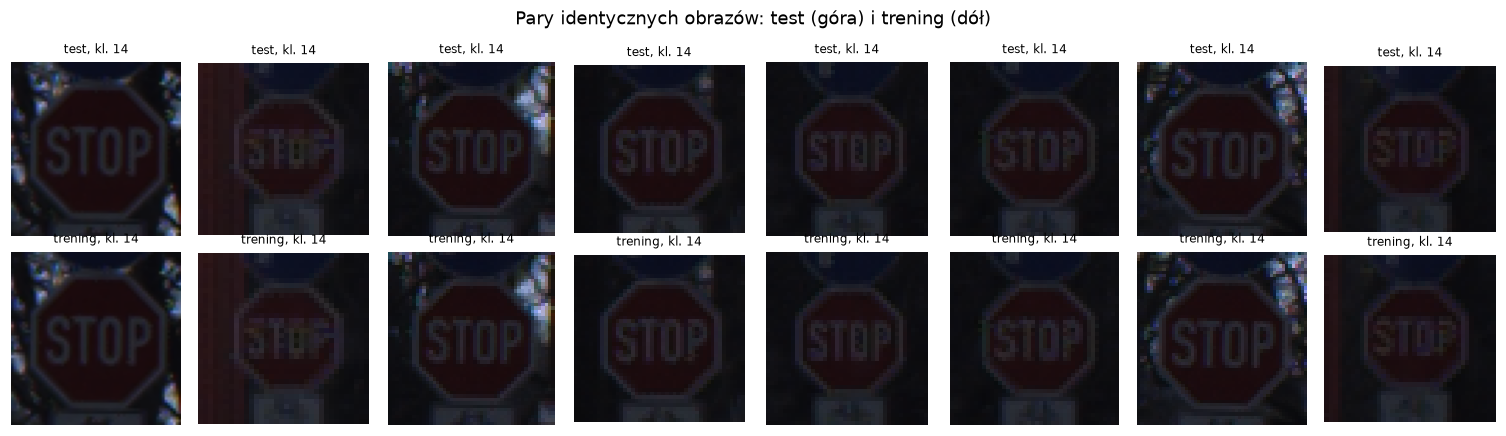

,Path,label,plik_treningowy,klasa_w_treningu,real_w,real_h
666,Test/00666.png,14,Train/14/00014_00023_00019.png,14,61,62
2291,Test/02291.png,14,Train/14/00014_00023_00000.png,14,34,34
3546,Test/03546.png,14,Train/14/00014_00023_00013.png,14,49,51
3594,Test/03594.png,14,Train/14/00014_00023_00010.png,14,45,44
4548,Test/04548.png,14,Train/14/00014_00023_00006.png,14,40,43
9384,Test/09384.png,14,Train/14/00014_00023_00007.png,14,42,43
9575,Test/09575.png,14,Train/14/00014_00023_00016.png,14,54,55
11906,Test/11906.png,14,Train/14/00014_00023_00003.png,14,39,38


In [22]:
train_by_md5 = meta_train.dropna(subset=["md5"]).drop_duplicates("md5").set_index("md5")
leaks = meta_test[meta_test["md5"].isin(train_by_md5.index)]
if leaks.empty:
    print("Brak obrazów testowych identycznych z treningowymi.")
else:
    k = min(len(leaks), 10)
    fig, axes = plt.subplots(2, k, figsize=(1.6 * k + 1, 4), squeeze=False)
    for j, (_, t) in enumerate(leaks.head(k).iterrows()):
        tr = train_by_md5.loc[t["md5"]]
        axes[0, j].imshow(gu.load_image(t["file"]))
        axes[0, j].set_title(f"test, kl. {t['label']}", fontsize=8)
        axes[1, j].imshow(gu.load_image(tr["file"]))
        axes[1, j].set_title(f"trening, kl. {tr['label']}", fontsize=8)
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle("Pary identycznych obrazów: test (góra) i trening (dół)")
    fig.tight_layout()
    gu.savefig(fig, "01_train_test_leaks")
    plt.show()
    display(leaks.assign(plik_treningowy=leaks["md5"].map(train_by_md5["Path"]),
                         klasa_w_treningu=leaks["md5"].map(train_by_md5["label"]))
                 [["Path", "label", "plik_treningowy", "klasa_w_treningu", "real_w", "real_h"]])

In [23]:
labels_per_track = meta_train.groupby("track_id")["label"].nunique()
print(f"Serie z więcej niż jedną klasą: {(labels_per_track > 1).sum()} (powinno być 0)")
print("Rozkład liczby klatek w serii:")
track_sizes.value_counts().sort_index()

Serie z więcej niż jedną klasą: 0 (powinno być 0)
Rozkład liczby klatek w serii:


29       1
30    1306
Name: count, dtype: int64

### Zapis metadanych
Zapisujemy tabelę metadanych (bez miniatur) do `data/processed/meta.csv`. Notatnik 02 użyje jej do podziału na trening i walidację po seriach (`track_id`), do wag klas i do wycinania znaku po ramce ROI.

In [24]:
out_path = gu.PROCESSED_DIR / "meta.csv"
meta.drop(columns=["error"], errors="ignore").to_csv(out_path, index=False)
print(f"Zapisano {len(meta)} wierszy do {out_path}")

Zapisano 51839 wierszy do /home/wojtazk/Desktop/gtsrb-robustness/data/processed/meta.csv


## 2.5 Podsumowanie i wnioski

Najważniejsze liczby w jednym miejscu (do raportu i prezentacji):

In [25]:
summary = {
    "obrazy treningowe": len(meta_train),
    "obrazy testowe": len(meta_test),
    "liczba klas": int(meta["label"].nunique()),
    "serie (fizyczne znaki) w treningu": int(track_sizes.size),
    "mediana klatek na serię": float(track_sizes.median()),
    "najmniej serii w klasie": f"{tracks_per_class.min()} (klasa {tracks_per_class.idxmin()})",
    "najmniej / najbardziej liczna klasa (trening)": f"{counts['train'].min()} / {counts['train'].max()}",
    "współczynnik niezbalansowania": round(float(imbalance), 1),
    "korelacja rozkładu klas trening-test": round(float(corr), 3),
    "mediana rozmiaru (szer. × wys.)": f"{meta['real_w'].median():.0f} × {meta['real_h'].median():.0f}",
    "obrazy z krótszym bokiem < 32 px": f"{(min_side < 32).mean():.1%}",
    "mediana udziału znaku (ROI) w obrazie": f"{meta['roi_area_frac'].median():.0%}",
    "problemy ze spójnością CSV ↔ pliki": quality["pliki z CSV, których nie ma na dysku"] + quality["obrazy na dysku nieopisane w CSV"],
    "pliki nieczytelne": quality["pliki nieczytelne (uszkodzone)"],
    "przeciek test w trening (identyczne obrazy)": quality["obrazy testowe identyczne z treningowymi (przeciek)"],
}
pd.Series(summary, name="wartość").to_frame()

,wartość
obrazy treningowe,39209
obrazy testowe,12630
liczba klas,43
serie (fizyczne znaki) w treningu,1307
mediana klatek na serię,30.0
najmniej serii w klasie,7 (klasa 0)
najmniej / najbardziej liczna klasa (trening),210 / 2250
współczynnik niezbalansowania,10.7
korelacja rozkładu klas trening-test,0.999
mediana rozmiaru (szer. × wys.),43 × 43


### Wnioski z eksploracji

*Liczby z pełnego uruchomienia na GTSRB (27.10.2026). Jeśli po zmianach w danych tabela podsumowania pokaże inne wartości, zaktualizujcie ten tekst.*

1. **Kompletność i spójność:** 39 209 obrazów treningowych i 12 630 testowych, 43 klasy. Wszystkie pliki z CSV istnieją i dają się otworzyć, rozmiary w CSV zgadzają się z obrazami, wszystkie ramki ROI są poprawne, folder i nazwa pliku zawsze zgadzają się z klasą. Foldery pisane małą literą są kopiami i można je usunąć.
2. **Niezbalansowanie klas:** od 210 obrazów (klasa 0, ograniczenie 20 km/h) do 2250 (klasa 2, ograniczenie 50 km/h) – współczynnik 10,7. Rozkład klas w teście jest praktycznie taki sam jak w treningu (korelacja udziałów 0,999), więc test dobrze odzwierciedla trening.
3. **Serie zdjęć:** trening to 1307 serii po 30 klatek (jedna seria ma 29), czyli tylko **1307 różnych fizycznych znaków**. Najrzadsza klasa (0) ma zaledwie 7 serii – przy podziale po seriach walidacja dostanie z niej 1–2 znaki.
4. **Rozmiary i jakość obrazów:** mediana rozmiaru 43×43 px, 17% obrazów ma krótszy bok poniżej 32 px, a 62% poniżej 48 px. Znak zajmuje ok. 57% powierzchni obrazu, margines tła to zwykle 5 px. Aż 20,5% obrazów jest bardzo ciemnych (średnia jasność < 0,15) – jasność to realny problem tego zbioru.
5. **Przeciek:** 8 obrazów testowych jest identycznych piksel w piksel z obrazami treningowymi (pary pokazane w sekcji 2.4). To 0,06% testu, więc wpływ na wynik jest pomijalny, ale warto to odnotować w raporcie.
6. **Kształt i kolor (Meta):** kod kształtu 0 = trójkąt ostrzegawczy, 1 = koło, 2 = romb (droga z pierwszeństwem), 3 = ośmiokąt (STOP), 4 = odwrócony trójkąt (ustąp pierwszeństwa); kod koloru 0 = czerwony, 1 = niebieski, 2 = żółty, 3 = biało-szary (odwołania). Kształt i kolor same rozdzielają grupy znaków – trudność leży wewnątrz grup (cyfry na ograniczeniach, piktogramy w trójkątach).
7. **PCA:** 43 składowe z 3072 wyjaśniają 90% wariancji pikseli, ale na dwóch pierwszych składowych grupy znaków się mieszają – liniowy model na surowych pikselach nie wystarczy, potrzebne są sieci konwolucyjne.
8. **Podobne klasy:** [uzupełnić po obejrzeniu średnich obrazów klas – które są niemal identyczne; kandydaci do pomyłek i ataków celowanych].

### Konsekwencje dla Data Preparation (notatnik 02)

| Obserwacja | Decyzja w przygotowaniu danych |
|---|---|
| różne rozmiary obrazów (mediana 43×43, 17% poniżej 32 px) | skalowanie do stałego rozmiaru; 32×32 to standard w literaturze, 48×48 zachowa więcej szczegółów cyfr – warto porównać oba |
| ramka ROI i margines tła | porównać dwa warianty: cały obraz vs wycięcie znaku po ROI (z małym marginesem) |
| różna jasność i kontrast, 20% bardzo ciemnych obrazów | normalizacja kanałów (średnia / odchylenie z treningu); sprawdzić wyrównanie histogramu (CLAHE) |
| 8 obrazów testowych identycznych z treningowymi | usunąć je z testu albo opisać w raporcie |
| serie zdjęć tego samego znaku | walidacja wydzielona **po seriach** (`track_id`, np. `GroupShuffleSplit`), nigdy losowo po obrazach |
| niezbalansowane klasy, mało serii w rzadkich klasach | wagi klas w funkcji straty lub oversampling; metryka macro-F1 |
| znaczenie kierunku i koloru | **bez odbić lustrzanych** (zakręt w lewo ↔ w prawo zmienia klasę) i bez silnej zmiany barw (kolor niesie znaczenie); dozwolone: lekkie obroty, przesunięcia, zmiana jasności |
| brak gotowych zakłóceń | zakłócenia (notatnik 04) generujemy **tylko dla zbioru testowego**, żeby ocena odporności była uczciwa |
| duplikaty folderów w archiwum | foldery pisane małą literą można usunąć, jeśli sekcja 2.1 potwierdziła, że to kopie |

### Literatura
- Stallkamp J., Schlipsing M., Salmen J., Igel C. (2012). *Man vs. computer: Benchmarking machine learning algorithms for traffic sign recognition.* Neural Networks 32, 323–332.
- Eykholt K. i in. (2018). *Robust Physical-World Attacks on Deep Learning Visual Classification.* CVPR.
- Goodfellow I., Shlens J., Szegedy C. (2015). *Explaining and Harnessing Adversarial Examples.* ICLR.
- Madry A. i in. (2018). *Towards Deep Learning Models Resistant to Adversarial Attacks.* ICLR.
- Hendrycks D., Dietterich T. (2019). *Benchmarking Neural Network Robustness to Common Corruptions and Perturbations.* ICLR.
- Chapman P. i in. (2000). *CRISP-DM 1.0: Step-by-step data mining guide.*